# 01 — Exploratory Data Analysis (EDA)

### Objective
To analyze customer churn patterns and identify the key factors that influence the likelihood of customers discontinuing their use of the service.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_style("white")

## Load Dataset

In [2]:
df = pd.read_csv("../dataset/WA_Fn-UseC_-Telco-Customer-Churn.csv")

## Data Understanding

### Checking the dataset size

In [3]:
df.shape

(7043, 21)

### Displaying the first 5 rows

In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


### Dataset information

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Descriptive Statistics

In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


The dataset consists of 21 columns containing customer information from a telecommunications company, grouped into five main categories:

- **Customer Profile**: Customer characteristics, such as gender, senior citizen status, partner status, and dependents.
- **Service Information**: Services used by customers, such as phone services, internet services, and technical support.
- **Contract Information**: Contract types and subscription duration.
- **Billing Information**: Billing and payment details, such as monthly charges, total charges, and payment methods.
- **Churn Status**: Indicates whether a customer has discontinued the service or remains subscribed.

## Data Cleaning

### Missing value check

In [7]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [8]:
(df == " ").sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

The initial examination revealed that the `TotalCharges` column contained blank spaces that were not detected as missing values. These values were replaced with NaN, and the column was converted to a numeric data type for analysis. The missing values were then handled using median imputation.

### Replacing blank spaces with NaN

In [9]:
df["TotalCharges"] = df["TotalCharges"].replace(" ", np.nan)

In [10]:
(df == " ").sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

### Converting TotalCharges to numeric

In [11]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"])

In [12]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Handling missing value

In [13]:
df.isnull().sum()

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [14]:
df.loc[df["TotalCharges"].isna(), ["tenure", "MonthlyCharges", "TotalCharges"]]

,tenure,MonthlyCharges,TotalCharges
488,0,52.55,NaN
753,0,20.25,NaN
936,0,80.85,NaN
1082,0,25.75,NaN
1340,0,56.05,NaN
3331,0,19.85,NaN
3826,0,25.35,NaN
4380,0,20.00,NaN
5218,0,19.70,NaN
6670,0,73.35,NaN


In [15]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

In [16]:
df["TotalCharges"].isna().sum()

np.int64(0)

In [17]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## Duplicate check

In [18]:
df.duplicated().sum()

np.int64(0)

No duplicate rows were found in the dataset, so no duplicate removal was necessary.

## Exploratory Data Analysis (EDA)

### Target Variable Transformation
Examining churn distribution

In [19]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

The `Churn` variable was converted from categorical to numerical values, where 0 represents customers who remained subscribed (No) and 1 represents customers who discontinued the service (Yes). This transformation was performed to simplify churn rate calculations in subsequent analyses.

In [20]:
df["Churn"] = df["Churn"].map({
        "No":0,
        "Yes":1
    }
)

In [21]:
df["Churn"].value_counts()

Churn
0    5174
1    1869
Name: count, dtype: int64

### Customer Churn Distribution
**Question:** "What is the distribution of customers by churn status?"

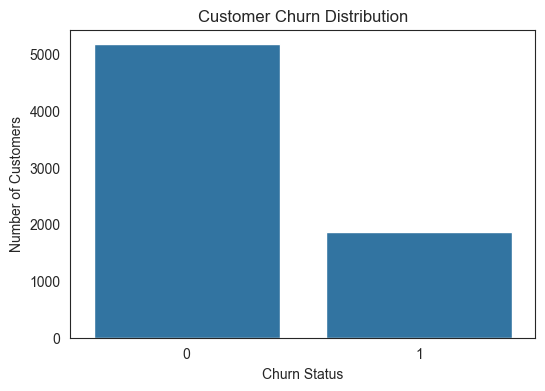

In [22]:
plt.figure(figsize=(6,4))
sns.countplot(data=df, x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn Status")
plt.ylabel("Number of Customers")
plt.grid(False)
plt.show()

In [23]:
churn_percentage = (df["Churn"].value_counts(normalize=True)*100)

A total of 26.54% of customers experienced churn, while 73.46% remained subscribed to the service. This indicates a class imbalance, with non-churned customers outnumbering churned customers. Therefore, a predictive model is needed to help identify customers at risk of churning at an earlier stage.

### Contract vs Churn
**Question:** "What is the relationship between contract type and customer churn rate?"

In [24]:
contract_churn = (df.groupby("Contract")["Churn"].mean()*100)

Customer contract types are divided into three categories:

- **Month-to-month:** A monthly contract that is renewed every month.
- **One year:** A subscription contract with a one-year duration.
- **Two year:** A subscription contract with a two-year duration.

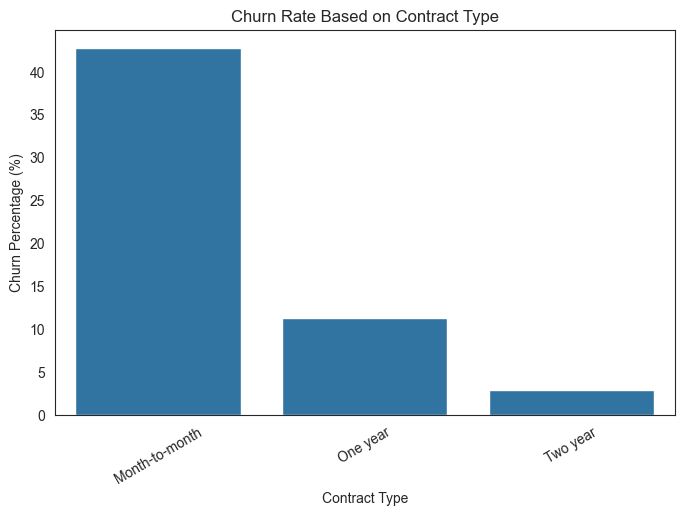

In [25]:
plt.figure(figsize=(8,5))
sns.barplot(x=contract_churn.index, y=contract_churn.values)
plt.title("Churn Rate Based on Contract Type")
plt.ylabel("Churn Percentage (%)")
plt.xlabel("Contract Type")
plt.xticks(rotation=30)
plt.grid(False)
plt.show()

Customers with **month-to-month** contracts have the highest churn rate at 42.71%, followed by **one-year contracts** at 11.27%, while **two-year contracts** have the lowest churn rate at 2.83%. This pattern indicates that customers with shorter-term contracts are more likely to discontinue the service.

### Tenure vs Churn
**Question:** "What is the relationship between customer tenure and churn rate?"

In [26]:
df["TenureGroup"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72], labels=[
        "0-12 Months",
        "13-24 Months",
        "25-48 Months",
        "49-72 Months"
    ]
)

tenure_churn = (df.groupby("TenureGroup", observed=True)["Churn"].mean()*100)

`tenure` represents the length of time a customer has been subscribed to the service, measured in months. To simplify the analysis, customers were grouped into four categories based on their subscription duration:

- **0–12 Months:** Customers who have subscribed for 0–12 months.
- **13–24 Months:** Customers who have subscribed for 13–24 months.
- **25–48 Months:** Customers who have subscribed for 25–48 months.
- **49–72 Months:** Customers who have subscribed for 49–72 months.

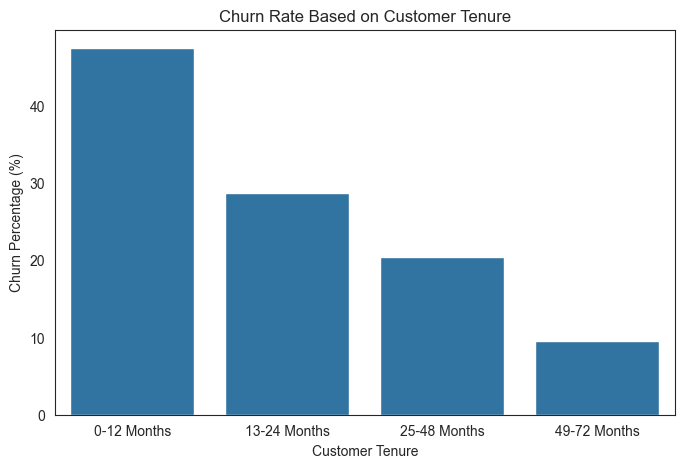

In [27]:
plt.figure(figsize=(8,5))
sns.barplot(x=tenure_churn.index, y=tenure_churn.values)
plt.title("Churn Rate Based on Customer Tenure")
plt.ylabel("Churn Percentage (%)")
plt.xlabel("Customer Tenure")
plt.grid(False)
plt.show()

Customers with a tenure of **0–12 months** have the highest churn rate at 47.44%, followed by those with **13–24 months** at 28.71% and **25–48 months** at 20.39%. Meanwhile, customers with a tenure of **49–72 months** have the lowest churn rate at 9.51%. This pattern indicates that customers with shorter subscription periods are more likely to churn, highlighting the importance of prioritizing these customers in retention strategies.

### Monthly Charges vs Churn
**Question:** "Are customers with higher monthly subscription charges more likely to churn?"

In [28]:
df["MonthlyChargesGroup"] = pd.cut(
    df["MonthlyCharges"],
    bins=[0, 35, 70, 90, float("inf")],
    labels=[
        "Low",
        "Medium",
        "High",
        "Very High"
    ]
)

monthly_churn = (df.groupby("MonthlyChargesGroup", observed=True)["Churn"].mean()*100)

Monthly subscription charges (`MonthlyCharges`) were grouped into four categories to simplify the analysis:

- **Low:** Monthly charges ≤ 35.
- **Medium:** Monthly charges greater than 35 and up to 70.
- **High:** Monthly charges greater than 70 and up to 90.
- **Very High:** Monthly charges greater than 90.

The category thresholds were defined for analytical purposes and do not represent the company's official classification.

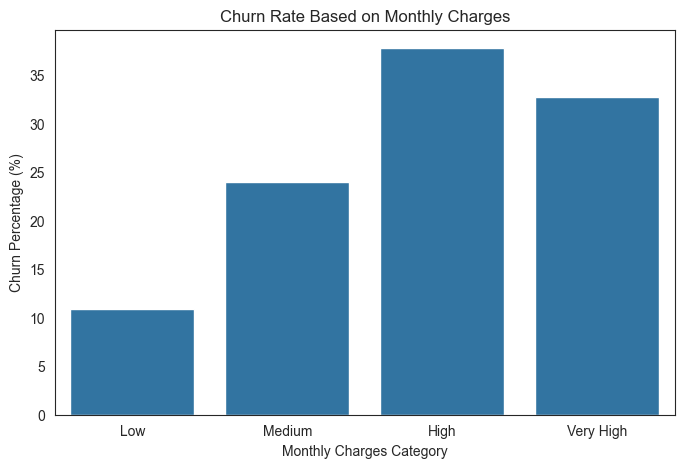

In [29]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=monthly_churn.index,
    y=monthly_churn.values
)

plt.title("Churn Rate Based on Monthly Charges")
plt.xlabel("Monthly Charges Category")
plt.ylabel("Churn Percentage (%)")
plt.grid(False)
plt.show()

Customers in the **High** monthly charges category have the highest churn rate at 37.80%, followed by **Very High** at 32.78%, **Medium** at 23.94%, and **Low** at 10.89%. Overall, customers with higher monthly charges tend to have higher churn rates than those with lower charges, although the Very High category shows a slightly lower churn rate than the High category.

### Internet Service vs Churn
**Question:** "Is the type of internet service used by customers associated with their churn rate?"

In [30]:
internet_churn = (df.groupby("InternetService")["Churn"].mean()*100)

Customer internet service types are divided into three categories:

- **DSL (Digital Subscriber Line):** An internet service that uses telephone lines to provide connectivity.
- **Fiber Optic:** An internet service that uses fiber-optic cables to provide high-speed connectivity.
- **No:** Customers who do not subscribe to the company's internet service.

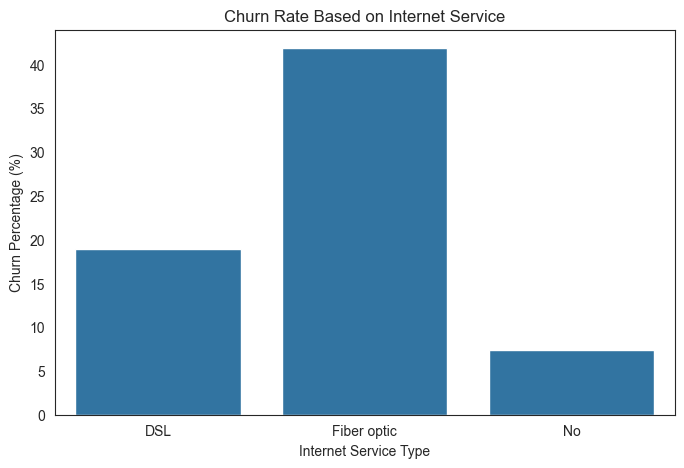

In [31]:
plt.figure(figsize=(8,5))

sns.barplot(
    x=internet_churn.index,
    y=internet_churn.values
)

plt.title("Churn Rate Based on Internet Service")
plt.xlabel("Internet Service Type")
plt.ylabel("Churn Percentage (%)")
plt.grid(False)
plt.show()

Customers using **Fiber optic** services have the highest churn rate at 41.89%, followed by **DSL** customers at 18.96%, while customers without internet service have the lowest churn rate at 7.40%. These findings indicate an association between internet service type and customer churn rate. However, further analysis is needed to determine whether these differences are also related to other factors, such as monthly charges and contract type.

In [32]:
df.to_csv("../dataset/clean_telco_churn.csv",index=False)

## EDA Conclusion

Based on the Exploratory Data Analysis (EDA), several key findings were identified:

1. **Customer Churn Distribution:** A total of 26.54% of customers experienced churn, while 73.46% remained subscribed to the service.
2. **Contract Type:** Customers with **Month-to-month** contracts had the highest churn rate at 42.71%.
3. **Customer Tenure:** Customers with a tenure of **0–12 months** had the highest churn rate at 47.44%, while those with **49–72 months** had the lowest churn rate at 9.51%.
4. **Monthly Charges:** Customers in the **High** monthly charges category had the highest churn rate at 37.80%.
5. **Internet Service Type:** Customers using **Fiber optic** services had the highest churn rate at 41.89% compared to other internet service categories.

These findings suggest that **contract type, customer tenure, monthly charges, and internet service type** are associated with customer churn rates. These insights provide a foundation for developing a machine learning model to predict customer churn risk and support effective customer retention strategies.